In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [49]:
df = pd.read_csv('titanic_train.csv')

In [50]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [51]:
df = df[['Survived', 'Age', 'Fare']]

In [52]:
df.isna().sum()

Survived      0
Age         177
Fare          0
dtype: int64

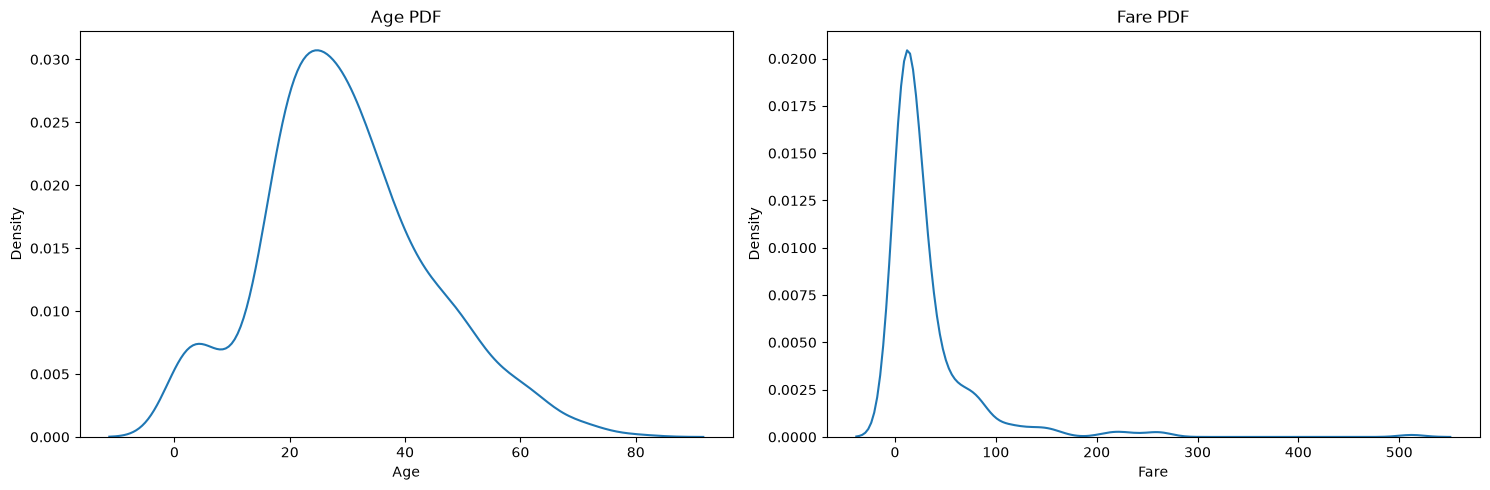

In [53]:
# before filling null values
fig, ax = plt.subplots(1, 2, figsize = (15,5))

sns.kdeplot(df['Age'], ax= ax[0], label = 'Age')
ax[0].set_title('Age PDF')

sns.kdeplot(df['Fare'], ax = ax[1])
ax[1].set_title('Fare PDF')

plt.tight_layout()

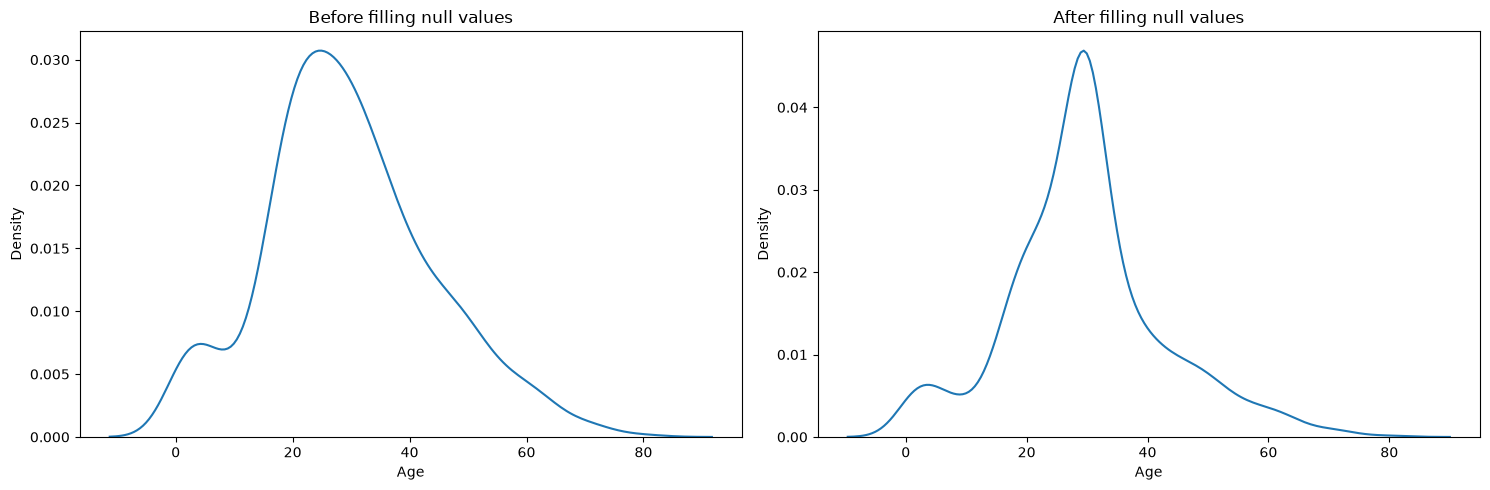

In [54]:
fig, ax = plt.subplots(1, 2, figsize = (15, 5))

sns.kdeplot(df['Age'], ax = ax[0])
ax[0].set_title('Before filling null values')

sns.kdeplot(df['Age'].fillna(df['Age'].mean()), ax = ax[1])
ax[1].set_title('After filling null values')

plt.tight_layout()

In [55]:
from sklearn.model_selection import train_test_split

In [56]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:, 1:], df.iloc[:, 0], test_size= 0.25, random_state= 42)

In [57]:
X_train.head()

,Age,Fare
298,NaN,30.5000
884,25.00,7.0500
247,24.00,14.5000
478,22.00,7.5208
305,0.92,151.5500


In [58]:
from sklearn.impute import SimpleImputer

In [59]:
si = SimpleImputer()

X_train = si.fit_transform(X_train)
X_test = si.transform(X_test)

In [60]:
X_train = pd.DataFrame(X_train, columns= df.columns[1:])
X_test = pd.DataFrame(X_test, columns = df.columns[1:])

In [61]:
X_train.isna().sum()

Age     0
Fare    0
dtype: int64

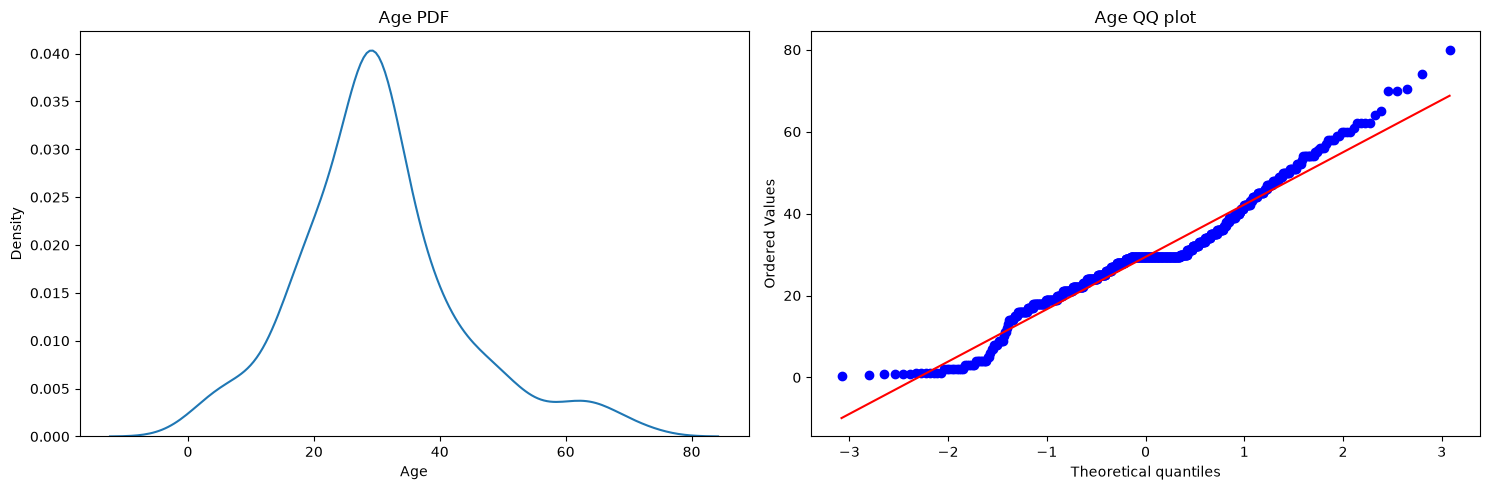

In [62]:
import scipy.stats as stats

fig, ax = plt.subplots(1, 2, figsize = (15 , 5))

sns.kdeplot(X_test['Age'], ax = ax[0])
ax[0].set_title('Age PDF')

stats.probplot(X_train['Age'], plot= ax[1])
ax[1].set_title('Age QQ plot')

plt.tight_layout()

Text(0.5, 1.0, 'Fare QQ plot')

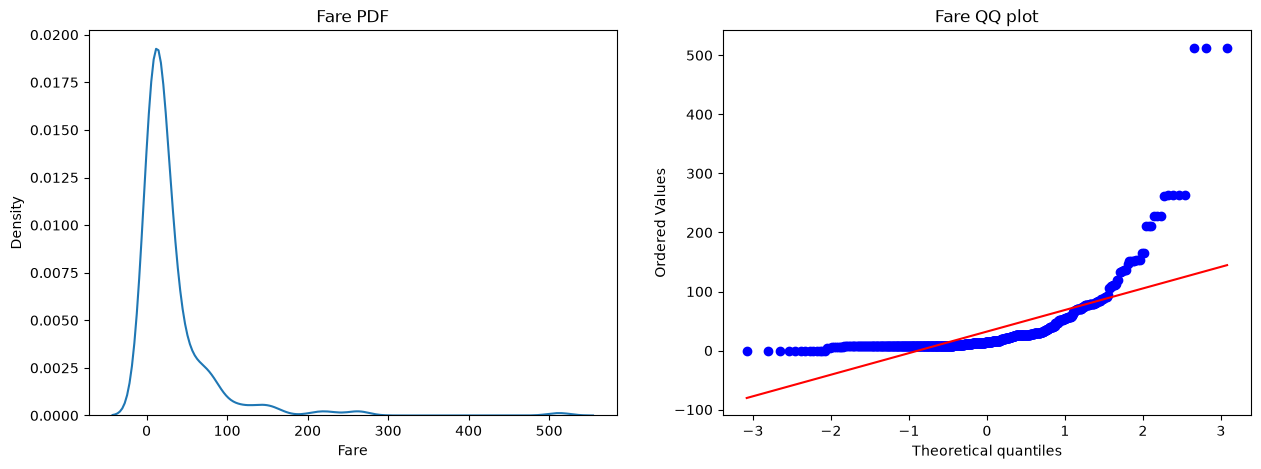

In [63]:
fig, ax = plt.subplots(1, 2, figsize = (15, 5))

sns.kdeplot(X_train['Fare'], ax = ax[0])
ax[0].set_title('Fare PDF')

stats.probplot(X_train['Fare'], plot = ax[1])
ax[1].set_title('Fare QQ plot')

In [64]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score

In [65]:
lg = LogisticRegression()
dt = DecisionTreeClassifier()

print('Logistic: ',cross_val_score(lg, X_train, y_train, scoring= 'accuracy', cv= 5).mean())
print('decision tree: ',cross_val_score(dt, X_train, y_train, scoring = 'accuracy', cv = 5).mean())

Logistic:  0.6496913926607564
decision tree:  0.624284592077208


In [66]:
# now preventing data leekage

In [67]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [68]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:, 1:], df.iloc[:, 0], test_size= 0.25, random_state= 42)

In [69]:
X_train.head()

,Age,Fare
298,NaN,30.5000
884,25.00,7.0500
247,24.00,14.5000
478,22.00,7.5208
305,0.92,151.5500


In [70]:
tfs = ColumnTransformer([
                            ('imputing', SimpleImputer(), ['Age'])
                        ], remainder= 'passthrough')

In [71]:
pipe = Pipeline([
                    ('tfs', tfs),
                    ('lg', lg)
                ])

In [72]:
print('Logistic: ',cross_val_score(pipe, X_train, y_train, scoring= 'accuracy', cv= 5).mean())
print('decision tree: ',cross_val_score(dt, X_train, y_train, scoring = 'accuracy', cv = 5).mean())

Logistic:  0.6496913926607564
decision tree:  0.6332510380428683


In [73]:
# now applying log transformer for fair column

In [74]:
from sklearn.preprocessing import FunctionTransformer

In [75]:
ft = FunctionTransformer(np.log1p)

X_train_trans = ft.fit_transform(X_train['Fare'])

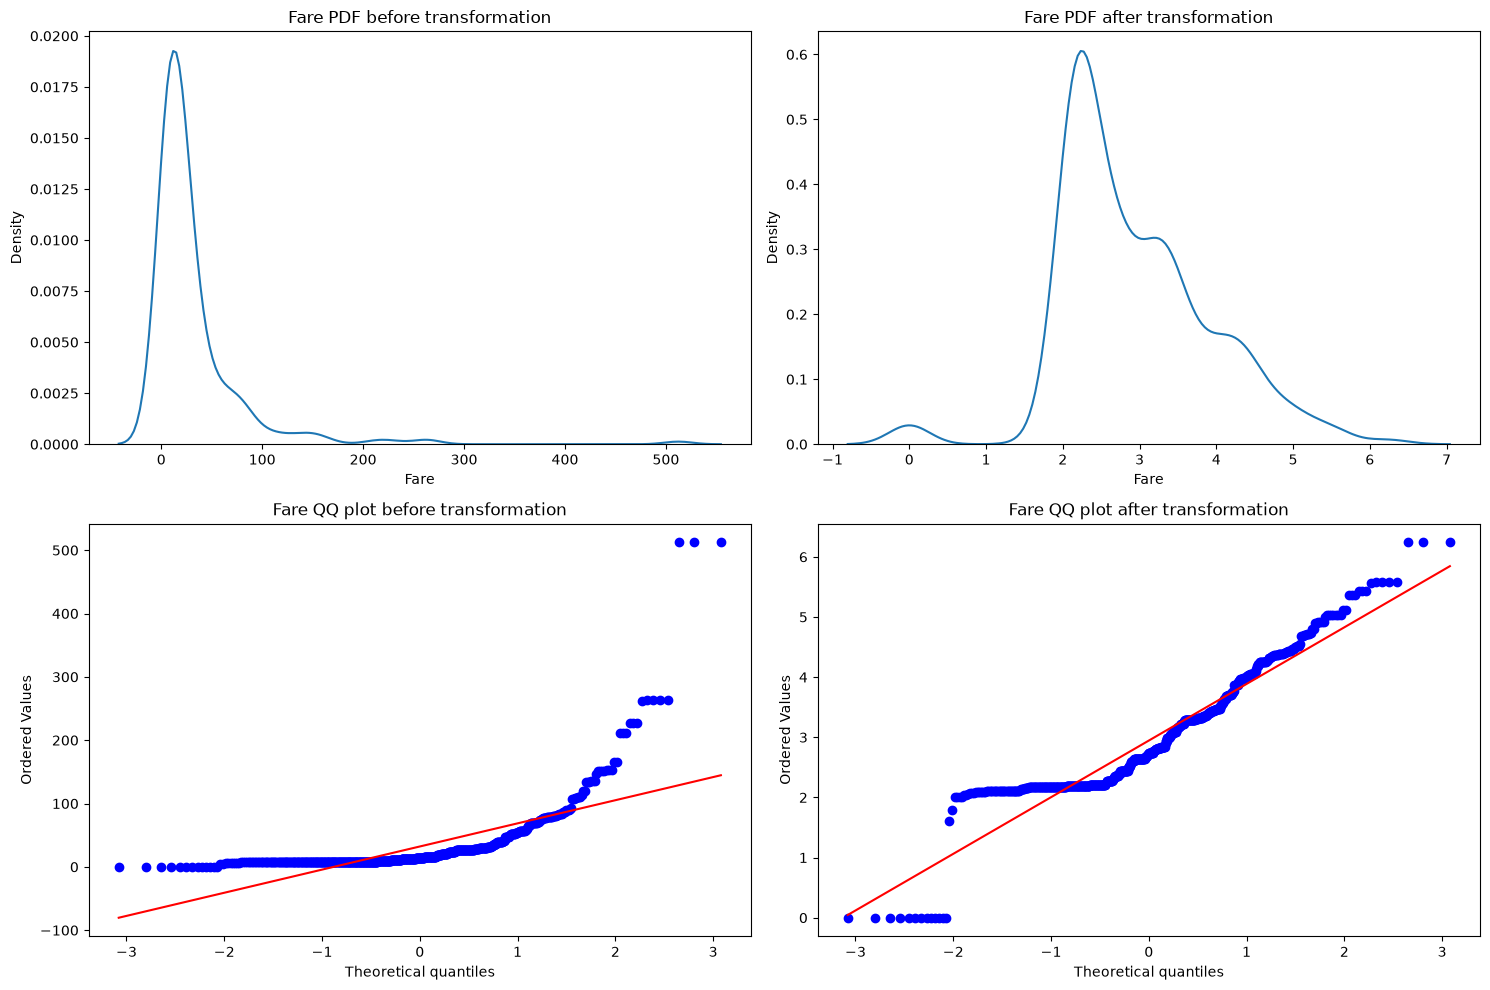

In [80]:
fig, ax = plt.subplots(2, 2, figsize = (15, 10))

sns.kdeplot(X_train['Fare'], ax = ax[0, 0])
ax[0, 0].set_title('Fare PDF before transformation')

sns.kdeplot(X_train_trans, ax = ax[0, 1])
ax[0, 1].set_title('Fare PDF after transformation')

stats.probplot(X_train['Fare'], plot = ax[1, 0])
ax[1, 0].set_title('Fare QQ plot before transformation')

stats.probplot(X_train_trans, plot = ax[1, 1])
ax[1, 1].set_title('Fare QQ plot after transformation')

plt.tight_layout()

In [81]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:, 1:], df.iloc[:, 0], test_size= 0.25, random_state= 42)

In [82]:
X_train.head()

,Age,Fare
298,NaN,30.5000
884,25.00,7.0500
247,24.00,14.5000
478,22.00,7.5208
305,0.92,151.5500


In [83]:
tfs = ColumnTransformer([
                            ('missing', SimpleImputer(), ['Age']),
                            ('log', FunctionTransformer(np.log1p), ['Fare'])
                        ])

In [84]:
pipe = Pipeline([
                    ('transformation', tfs),
                    ('log', lg)
                ])

In [86]:
print("log:", cross_val_score(pipe, X_train, y_train, scoring= 'accuracy', cv = 5).mean())
print('tree:', cross_val_score(dt, X_train, y_train, scoring = 'accuracy', cv = 5).mean())

log: 0.6601503759398496
tree: 0.6392324093816633
